# Notebook 04 — Task T10: Chốt Mô hình và Đánh giá trên Tập Holdout Test Chung

> **Học phần:** Phân tích và Trực quan hóa Dữ liệu (IE313)  
> **Thành viên thực hiện phối hợp:** Thành viên A + Thành viên B (A+B Task)  
> **Giao thức thực nghiệm:** `ie313_raw_v1_seed0_cv5` ([config/experiment_config.json](../config/experiment_config.json))  
> **Nguyên tắc Liêm chính Học thuật:**  
> 1. Mô hình được chốt hoàn toàn dựa trên $CV\_MSE$ trên tập Train; **tuyệt đối không dùng kết quả Test để tinh chỉnh siêu tham số**.  
> 2. Đánh giá độc lập trên toàn bộ **10.342 dòng Holdout Test** (`cv_fold = -1`) nguyên bản, không clipping, không loại bỏ ngoại lệ.

Giới hạn: holdout tách khỏi train theo dòng, chưa xác minh độc lập theo listing vì không có listing ID; tọa độ có thể lặp. Các metric test là đánh giá sau chọn bằng CV, không dùng để chỉnh mô hình.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src' / 'experiment.py').exists(), 'Mở notebook từ thư mục gốc hoặc thư mục notebooks/'
sys.path.insert(0, str(ROOT))

from src.experiment import load_protocol, predictor_names
from src.t10_tasks import (
    load_combined_cv_summary, evaluate_models_on_test,
    plot_t10_figures, write_t10_reports
)

config, train, test, cv = load_protocol(ROOT)
print(f"Giao thức chuẩn: {config['protocol_id']}")
print(f"Quy mô tập Train (5-Fold CV): {len(train):,} dòng")
print(f"Quy mô tập Holdout Test: {len(test):,} dòng")
print(f"Thuộc tính dự báo Allowlist (10 biến): {predictor_names(config)}")

Giao thức chuẩn: ie313_raw_v1_seed0_cv5
Quy mô tập Train (5-Fold CV): 41,365 dòng
Quy mô tập Holdout Test: 10,342 dòng
Thuộc tính dự báo Allowlist (10 biến): ['person_capacity', 'bedrooms', 'dist', 'metro_dist', 'cleanliness_rating', 'guest_satisfaction_overall', 'city', 'day_type', 'room_type', 'host_is_superhost']


## 1. So chiếu Hiệu năng 5-Fold Cross-Validation & Khóa Mô hình Chiến thắng

Trước khi mở khóa tập Test, hai thành viên A và B cùng đối chiếu kết quả 5-Fold Cross-Validation trên tập Train (41.365 dòng):
- **Nhánh A:** M0 (Baseline Trung bình), M1 (SLR `person_capacity`), M2 (MLR 10 biến Allowlist).
- **Nhánh B:** M3 (Polynomial bậc 3 trên 3 biến cốt lõi), M4 (Ridge $\alpha=0.1$).

Mô hình đạt $CV\_MSE$ thấp nhất sẽ được chốt chính thức làm **Mô hình Chiến thắng (Winning Model)**.

In [2]:
cv_summary = load_combined_cv_summary(ROOT)
display_cols = ['model_id', 'variant', 'n_train', 'cv_mse_mean', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean', 'fold_train_mse_mean']
display(cv_summary[display_cols])

winner_cv = cv_summary.loc[cv_summary['cv_mse_mean'].idxmin()]
print("=== QUYẾT ĐỊNH CHỐT MÔ HÌNH DỰA TRÊN 5-FOLD CROSS-VALIDATION ===")
print(f"Mô hình chiến thắng: {winner_cv['model_id']} ({winner_cv['variant']})")
print(f"- CV MSE trung bình: {winner_cv['cv_mse_mean']:,.2f} EUR² (thấp nhất trong 5 mô hình)")
print(f"- CV R² trung bình: {winner_cv['cv_r2_mean']:.4f}")
print("-> KHÓA CỨNG CẤU HÌNH (LOCKED): Tuyệt đối không tinh chỉnh siêu tham số trên tập Test!")

,model_id,variant,n_train,cv_mse_mean,cv_rmse_mean,cv_mae_mean,cv_r2_mean,fold_train_mse_mean
0,M0,mean_baseline,41365,104402.753571,322.089212,146.407063,-0.000020,104401.928256
1,M1,slr_person_capacity,41365,99919.961727,314.986280,139.129094,0.044274,99918.568983
2,M2,mlr_10_features,41365,79988.148575,281.168391,104.351195,0.240876,79912.369755
3,M3,degree_3,41365,79227.997866,279.800136,102.940256,0.248306,78883.658389
4,M4,alpha_0.1,41365,79988.147660,281.168385,104.348604,0.240876,79912.371907


=== QUYẾT ĐỊNH CHỐT MÔ HÌNH DỰA TRÊN 5-FOLD CROSS-VALIDATION ===
Mô hình chiến thắng: M3 (degree_3)
- CV MSE trung bình: 79,228.00 EUR² (thấp nhất trong 5 mô hình)
- CV R² trung bình: 0.2483
-> KHÓA CỨNG CẤU HÌNH (LOCKED): Tuyệt đối không tinh chỉnh siêu tham số trên tập Test!


## 2. Mở khóa và Đánh giá Khách quan trên Tập Holdout Test (10.342 dòng)

Nạp 5 mô hình đã fit trên tập Train (thư mục `models/`), thực hiện dự đoán trên 10.342 dòng Test và tính toán 4 chỉ số thống kê:
- **Mean Squared Error (MSE):** Sai số toàn phương trung bình.
- **Root Mean Squared Error (RMSE):** Căn bậc hai của MSE (thang EUR).
- **Mean Absolute Error (MAE):** Sai số tuyệt đối trung bình (thang EUR).
- **Coefficient of Determination ($R^2$):** Tỷ lệ phương sai được giải thích trên tập Test.

In [3]:
comparison_df, test_preds_df, test_data = evaluate_models_on_test(ROOT)

test_summary_cols = ['model_id', 'variant', 'author', 'cv_mse_mean', 'test_mse', 'test_rmse', 'test_mae', 'test_r2', 'mse_gap_test_minus_cv']
display(comparison_df[test_summary_cols])

winner_test = comparison_df[comparison_df['selected_winning_model'] == True].iloc[0]
print("=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP ===")
print(f"Mô hình dẫn đầu: {winner_test['model_id']} ({winner_test['variant']})")
print(f"- Test MSE: {winner_test['test_mse']:,.2f} EUR²")
print(f"- Test RMSE: {winner_test['test_rmse']:.2f} EUR | Test MAE: {winner_test['test_mae']:.2f} EUR")
print(f"- Test R²: {winner_test['test_r2']:.4f}")

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP HOLDOUT TEST (10.342 dòng) ===
[M0] mean_baseline: Test MSE = 120,131.61 | Test RMSE = 346.60 | Test MAE = 144.86 | Test R2 = -0.0000
[M1] slr_person_capacity: Test MSE = 115,888.69 | Test RMSE = 340.42 | Test MAE = 137.12 | Test R2 = 0.0353
[M2] mlr_10_features: Test MSE = 97,964.14 | Test RMSE = 312.99 | Test MAE = 103.76 | Test R2 = 0.1845
[M3] degree_3 [WINNER]: Test MSE = 97,156.55 | Test RMSE = 311.70 | Test MAE = 102.02 | Test R2 = 0.1912
[M4] alpha_0.1: Test MSE = 97,963.94 | Test RMSE = 312.99 | Test MAE = 103.76 | Test R2 = 0.1845


,model_id,variant,author,cv_mse_mean,test_mse,test_rmse,test_mae,test_r2,mse_gap_test_minus_cv
0,M0,mean_baseline,Thành viên A,104402.753571,120131.607928,346.600069,144.857174,-0.000010,15728.854357
1,M1,slr_person_capacity,Thành viên A,99919.961727,115888.690541,340.424280,137.116888,0.035309,15968.728814
2,M2,mlr_10_features,Thành viên A,79988.148575,97964.136704,312.992231,103.763734,0.184518,17975.988129
3,M3,degree_3,Thành viên B,79227.997866,97156.549919,311.699454,102.024557,0.191241,17928.552053
4,M4,alpha_0.1,Thành viên B,79988.147660,97963.935381,312.991909,103.761672,0.184520,17975.787721


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP ===
Mô hình dẫn đầu: M3 (degree_3)
- Test MSE: 97,156.55 EUR²
- Test RMSE: 311.70 EUR | Test MAE: 102.02 EUR
- Test R²: 0.1912


## 3. Trực quan hóa So sánh Hiệu năng & Phân phối Sai số

- **Hình 1 (`fig_06`):** So sánh MSE và R² giữa Validation CV và Holdout Test cho cả 5 mô hình.
- **Hình 2 (`fig_07`):** Đồ thị mật độ phân phối (KDE Plot) giữa Giá thực tế và Giá dự đoán trên tập Test theo bài giảng Bài 6 tr. 15–20.

1. Biểu đồ so sánh hiệu năng CV vs Test:


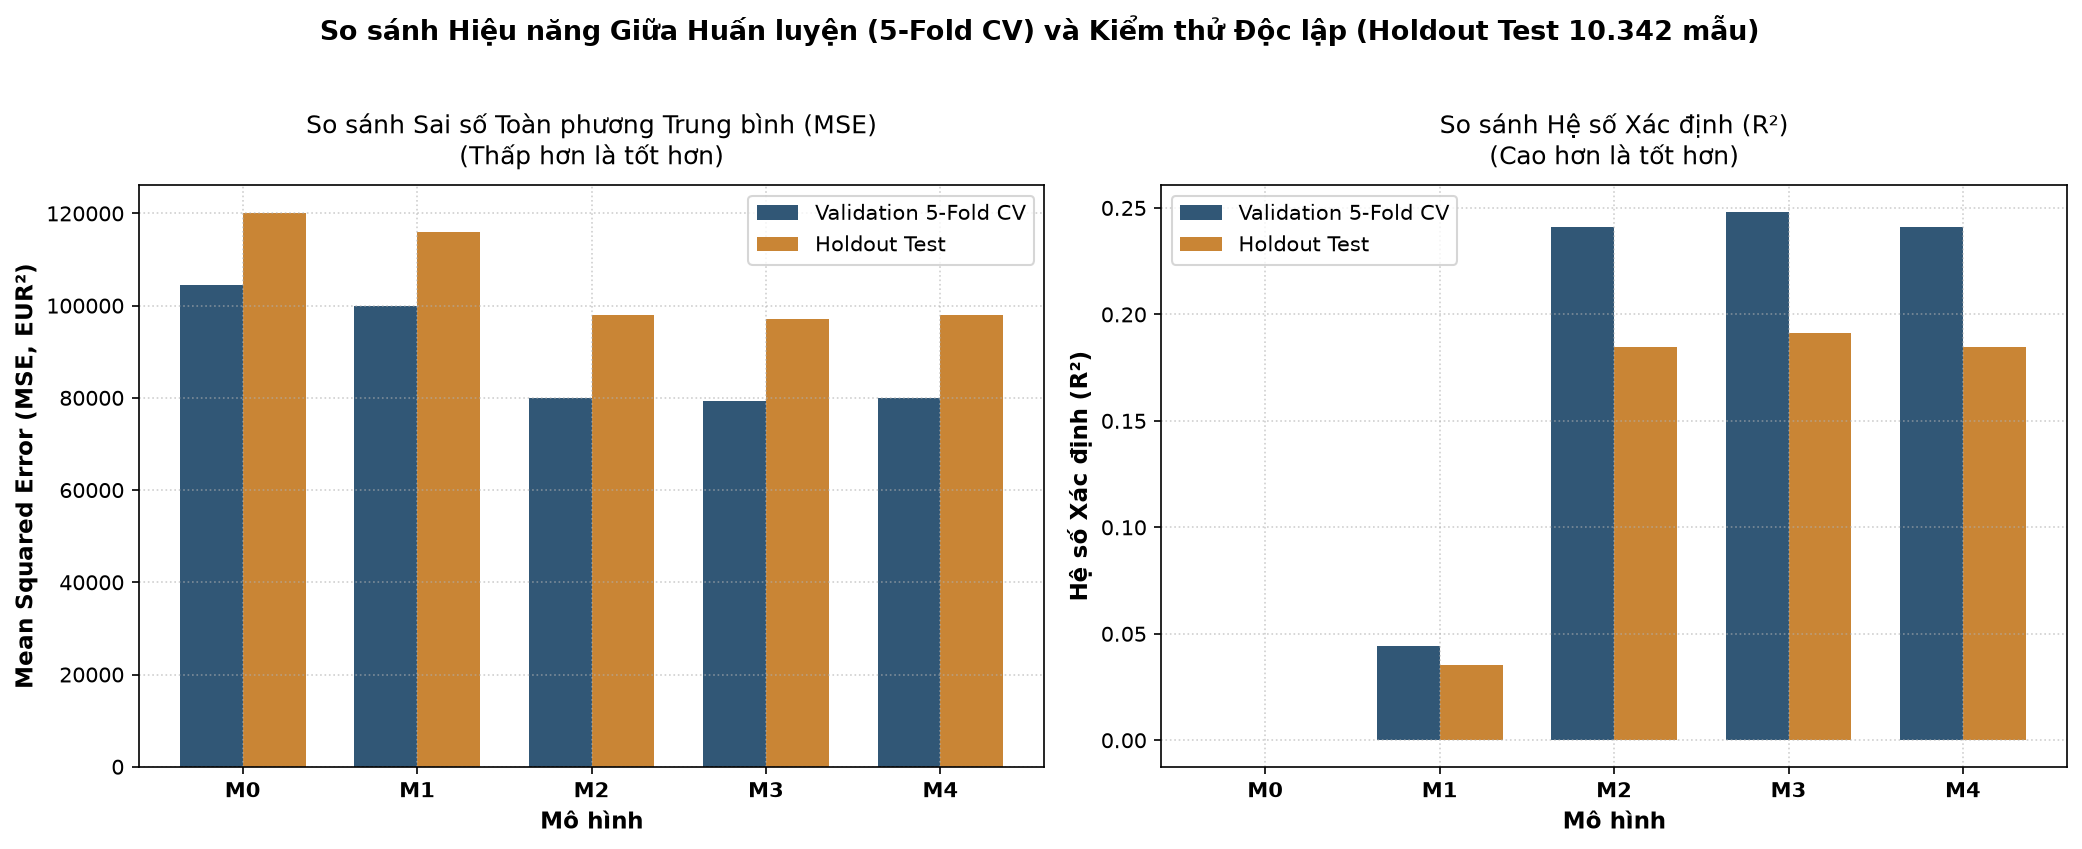

2. Biểu đồ mật độ phân phối Actual vs Predicted (KDE Plot):


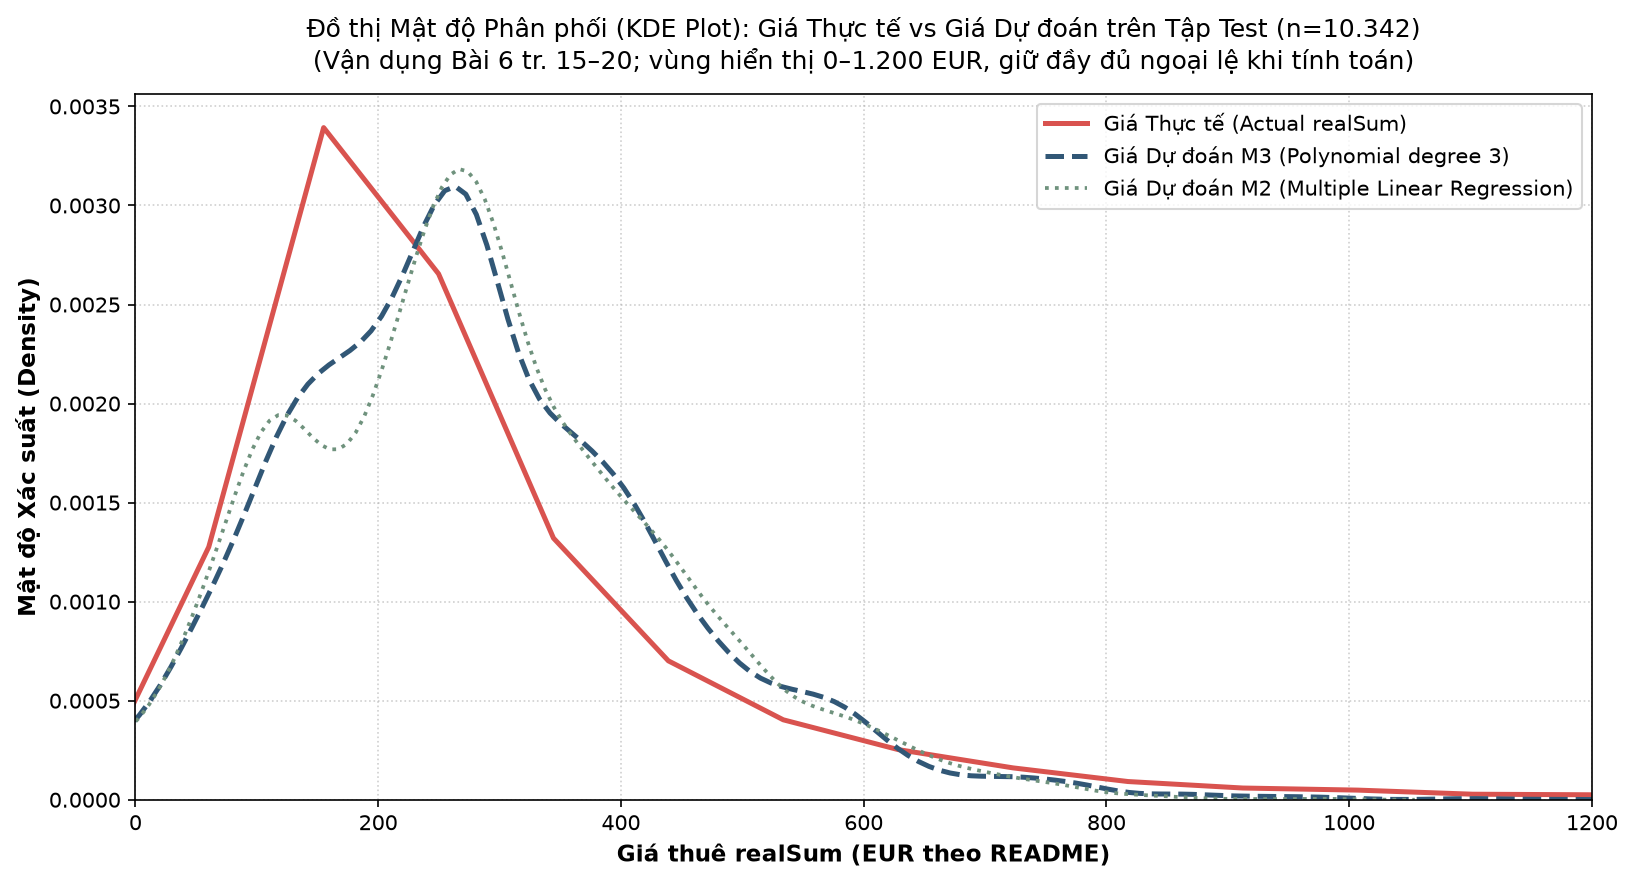

In [4]:
# Vẽ và lưu 2 biểu đồ trực quan
plot_t10_figures(comparison_df, test_preds_df, ROOT)

print("1. Biểu đồ so sánh hiệu năng CV vs Test:")
display(Image(filename=str(ROOT / 'outputs/figures/fig_06_cv_vs_test_comparison.png')))

print("2. Biểu đồ mật độ phân phối Actual vs Predicted (KDE Plot):")
display(Image(filename=str(ROOT / 'outputs/figures/fig_07_actual_vs_predicted_distribution.png')))

## 4. Xuất Tệp Dữ liệu Dự đoán `test_predictions.csv` Bàn giao cho Task T11

Tệp `outputs/tables/test_predictions.csv` chứa 10.342 dòng dự đoán kèm hai mã truy vết `source_file`, `source_row` và phần dư `residual = actual - predicted`. Tệp này được bàn giao trực tiếp cho Thành viên B thực hiện Task T11 (phân tích phần dư, sai số theo thành phố/loại phòng và case study).

In [5]:
print(f"Tổng số bản ghi dự đoán test: {len(test_preds_df):,} dòng (10.342 mẫu x 5 mô hình)")
display(test_preds_df.head(10))

# Xuất báo cáo học thuật và biên bản nghiệm thu
rep_path, acc_path = write_t10_reports(comparison_df, ROOT)
print(f"Đã xuất báo cáo tại: {rep_path.relative_to(ROOT)}")
print(f"Đã xuất biên bản nghiệm thu tại: {acc_path.relative_to(ROOT)}")

Tổng số bản ghi dự đoán test: 51,710 dòng (10.342 mẫu x 5 mô hình)


,source_file,source_row,model_id,variant,actual,predicted,residual,split,protocol_id
0,amsterdam_weekdays.csv,1,M0,mean_baseline,344.245776,280.100228,64.145548,test,ie313_raw_v1_seed0_cv5
1,amsterdam_weekdays.csv,3,M0,mean_baseline,433.529398,280.100228,153.429170,test,ie313_raw_v1_seed0_cv5
2,amsterdam_weekdays.csv,14,M0,mean_baseline,209.031472,280.100228,-71.068756,test,ie313_raw_v1_seed0_cv5
3,amsterdam_weekdays.csv,17,M0,mean_baseline,337.918590,280.100228,57.818362,test,ie313_raw_v1_seed0_cv5
4,amsterdam_weekdays.csv,18,M0,mean_baseline,313.547208,280.100228,33.446980,test,ie313_raw_v1_seed0_cv5
5,amsterdam_weekdays.csv,22,M0,mean_baseline,251.915731,280.100228,-28.184497,test,ie313_raw_v1_seed0_cv5
6,amsterdam_weekdays.csv,24,M0,mean_baseline,245.588545,280.100228,-34.511683,test,ie313_raw_v1_seed0_cv5
7,amsterdam_weekdays.csv,28,M0,mean_baseline,1032.971668,280.100228,752.871440,test,ie313_raw_v1_seed0_cv5
8,amsterdam_weekdays.csv,33,M0,mean_baseline,602.254353,280.100228,322.154125,test,ie313_raw_v1_seed0_cv5
9,amsterdam_weekdays.csv,34,M0,mean_baseline,504.065803,280.100228,223.965575,test,ie313_raw_v1_seed0_cv5


Đã xuất báo cáo tại: reports\t10_model_selection_and_test_evaluation.md
Đã xuất biên bản nghiệm thu tại: reports\A_B_T10_ACCEPTANCE.md


In [6]:
# === BỘ KIỂM THỬ NỘI BỘ TỰ ĐỘNG (IN-NOTEBOOK ASSERTIONS) CHO TASK T10 ===
print("Đang kiểm tra tính đúng đắn kỹ thuật của Task T10...")

# 1. Kiểm tra kích thước và tính toàn vẹn của tập test
assert len(comparison_df) == 5, f"Phải đánh giá đủ 5 mô hình, thực tế: {len(comparison_df)}"
assert len(test_preds_df) == 10342 * 5, f"Tổng số dòng dự đoán phải bằng 51.710, thực tế: {len(test_preds_df)}"

# 2. Kiểm tra đẳng thức toán học trên tập test (RMSE^2 == MSE)
for _, row in comparison_df.iterrows():
    diff = abs(row['test_rmse']**2 - row['test_mse'])
    assert diff < 1e-4, f"Lỗi toán học RMSE^2 != MSE trên test cho mô hình {row['model_id']}: {diff}"

# 3. Kiểm tra tính nhất quán thứ bậc trên tập test
m0_test_mse = comparison_df.loc[comparison_df.model_id == 'M0', 'test_mse'].iloc[0]
m1_test_mse = comparison_df.loc[comparison_df.model_id == 'M1', 'test_mse'].iloc[0]
m3_test_mse = comparison_df.loc[comparison_df.model_id == 'M3', 'test_mse'].iloc[0]
assert m3_test_mse < m1_test_mse < m0_test_mse, "Thứ bậc MSE trên test vi phạm M3 < M1 < M0"

# 4. Xác nhận mô hình chiến thắng là M3
assert winner_test['model_id'] == 'M3', f"Mô hình chiến thắng phải là M3, thực tế: {winner_test['model_id']}"

print("-> TẤT CẢ CÁC BÀI KIỂM THỬ TỰ ĐỘNG NỘI BỘ TASK T10 ĐÃ ĐẠT 100% (PASSED)!")

Đang kiểm tra tính đúng đắn kỹ thuật của Task T10...
-> TẤT CẢ CÁC BÀI KIỂM THỬ TỰ ĐỘNG NỘI BỘ TASK T10 ĐÃ ĐẠT 100% (PASSED)!
